In [1]:
# 5.6 RFM 用户分层可视化
# 5.6.1 数据读取与核验

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 项目路径
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data/processed/customer_rfm_segments.csv"
fig_dir = project_root / "reports/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# 读取数据
df = pd.read_csv(data_path, encoding="utf-8-sig")
df = df.sort_values("customer_segment").reset_index(drop=True)

# 核验数据完整性
assert len(df) == 7
assert df["customer_count"].sum() == 93104
assert df["total_orders"].sum() == 96211
assert abs(df["total_gmv"].sum() - 13181027.13) < 0.01

# 使用英文简写，避免绘图时中文字体兼容问题
df["segment"] = df["customer_segment"].str[0]

print(df)

  customer_segment  customer_count  customer_share_pct  total_orders  \
0        A_近期高消费复购             964                1.04          2122   
1         B_近期其他复购             575                0.62          1175   
2          C_非近期复购            1250                1.34          2599   
3        D_近期高消费单次           10728               11.52         10728   
4         E_近期其他单次           34413               36.96         34413   
5       F_非近期高消费单次           10873               11.68         10873   
6        G_非近期其他单次           34301               36.84         34301   

    total_gmv  gmv_share_pct  avg_customer_gmv  avg_recency_days segment  
0   351060.67           2.66            364.17            115.28       A  
1    55778.02           0.42             97.01            114.63       B  
2   318516.35           2.42            254.81            353.95       C  
3  3789929.72          28.75            353.27            114.31       D  
4  2447684.77          18.57             71.13  

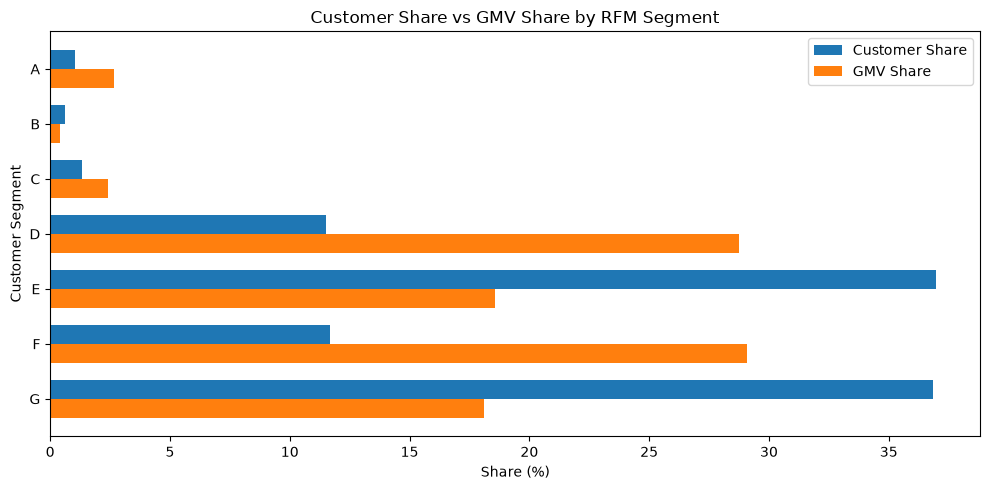

In [2]:
# 5.6.2 用户占比与 GMV 贡献对比

fig, ax = plt.subplots(figsize=(10, 5))

y = np.arange(len(df))
width = 0.35

ax.barh(
    y - width / 2,
    df["customer_share_pct"],
    height=width,
    label="Customer Share"
)

ax.barh(
    y + width / 2,
    df["gmv_share_pct"],
    height=width,
    label="GMV Share"
)

ax.set_yticks(y)
ax.set_yticklabels(df["segment"])
ax.invert_yaxis()

ax.set_xlabel("Share (%)")
ax.set_ylabel("Customer Segment")
ax.set_title("Customer Share vs GMV Share by RFM Segment")
ax.legend()

plt.tight_layout()

plt.savefig(
    fig_dir / "customer_segment_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

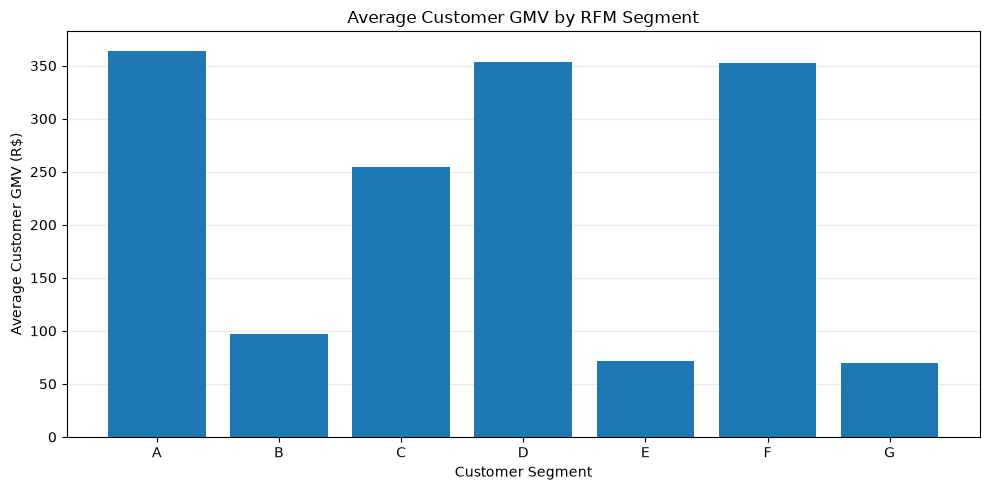

In [3]:
# 5.6.3 不同用户群体平均消费金额

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    df["segment"],
    df["avg_customer_gmv"]
)

ax.set_xlabel("Customer Segment")
ax.set_ylabel("Average Customer GMV (R$)")
ax.set_title("Average Customer GMV by RFM Segment")

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "customer_segment_avg_gmv.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()